In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
Clean_Data_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data")
Table_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables")
Chart_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts")

print("Clean data:", Clean_Data_Path)
print("Output tables:", Table_Path)
print("Output charts:", Chart_Path)

Clean data: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data
Output tables: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables
Output charts: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts


In [3]:
customers = pd.read_csv(
    Clean_Data_Path / "customers_clean.csv"
)

orders = pd.read_csv(
    Clean_Data_Path / "orders_clean.csv"
)

order_items = pd.read_csv(
    Clean_Data_Path / "order_items_clean.csv"
)

reviews = pd.read_csv(
    Clean_Data_Path / "reviews_clean.csv"
)

payments = pd.read_csv(
    Clean_Data_Path / "payments_clean.csv"
)

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Reviews:", reviews.shape)
print("Payments:", payments.shape)

Customers: (99441, 5)
Orders: (96461, 8)
Order items: (112650, 7)
Reviews: (99224, 7)
Payments: (103886, 5)


In [4]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

In [5]:
order_value = (
    order_items
    .groupby("order_id", as_index=False)
    .agg(
        order_revenue=("price", "sum"),
        order_freight=("freight_value", "sum"),
        item_count=("order_item_id", "count")
    )
)

order_value["order_total_value"] = (
    order_value["order_revenue"]
    + order_value["order_freight"]
)

print(order_value.head())
print("Order-level rows:", len(order_value))

                           order_id  order_revenue  order_freight  item_count  \
0  00010242fe8c5a6d1ba2dd792cb16214          58.90          13.29           1   
1  00018f77f2f0320c557190d7a144bdd3         239.90          19.93           1   
2  000229ec398224ef6ca0657da4fc703e         199.00          17.87           1   
3  00024acbcdf0a6daa1e931b038114c75          12.99          12.79           1   
4  00042b26cf59d7ce69dfabb4e55b4fd9         199.90          18.14           1   

   order_total_value  
0              72.19  
1             259.83  
2             216.87  
3              25.78  
4             218.04  
Order-level rows: 98666


In [6]:
customer_orders = orders[
    [
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date"
    ]
].merge(
    order_value,
    on="order_id",
    how="left"
)

customer_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_revenue,order_freight,item_count,order_total_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,29.99,8.72,1,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,118.70,22.76,1,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,159.90,19.22,1,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,45.00,27.20,1,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,19.90,8.72,1,28.62


In [7]:
customer_orders = customer_orders.merge(
    customers[
        [
            "customer_id",
            "customer_unique_id",
            "customer_city",
            "customer_state"
        ]
    ],
    on="customer_id",
    how="left"
)

print(customer_orders.shape)
customer_orders.head()

(96461, 12)


,order_id,customer_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_revenue,order_freight,item_count,order_total_value,customer_unique_id,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,29.99,8.72,1,38.71,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,118.70,22.76,1,141.46,af07308b275d755c9edb36a90c618231,barreiras,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,159.90,19.22,1,179.12,3a653a41f6f9fc3d2a113cf8398680e8,vianopolis,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-12-02 00:28:42,45.00,27.20,1,72.20,7c142cf63193a1473d2e66489a9ae977,sao goncalo do amarante,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-16 18:17:02,19.90,8.72,1,28.62,72632f0f9dd73dfee390c9b22eb56dd6,santo andre,SP


In [8]:
customer_base = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique"),
        total_revenue=("order_revenue", "sum"),
        total_freight=("order_freight", "sum"),
        total_spend=("order_total_value", "sum"),
        total_items=("item_count", "sum"),
        first_purchase=("order_purchase_timestamp", "min"),
        last_purchase=("order_purchase_timestamp", "max"),
        customer_state=("customer_state", "first"),
        customer_city=("customer_city", "first")
    )
    .reset_index()
)

customer_base.head()

,customer_unique_id,order_count,total_revenue,total_freight,total_spend,total_items,first_purchase,last_purchase,customer_state,customer_city
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,12.00,141.90,1,2018-05-10 10:56:27,2018-05-10 10:56:27,SP,cajamar
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,8.29,27.19,1,2018-05-07 11:11:27,2018-05-07 11:11:27,SP,osasco
2,0000f46a3911fa3c0805444483337064,1,69.00,17.22,86.22,1,2017-03-10 21:05:03,2017-03-10 21:05:03,SC,sao jose
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,17.63,43.62,1,2017-10-12 20:29:41,2017-10-12 20:29:41,PA,belem
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,16.89,196.89,1,2017-11-14 19:45:42,2017-11-14 19:45:42,SP,sorocaba


In [9]:
customer_base["customer_lifetime_days"] = (
    customer_base["last_purchase"]
    - customer_base["first_purchase"]
).dt.days

In [10]:
customer_base["customer_aov"] = (
    customer_base["total_revenue"]
    / customer_base["order_count"]
)

In [11]:
review_summary = (
    reviews
    .groupby("order_id", as_index=False)
    .agg(
        review_score=("review_score", "mean")
    )
)

review_summary.head()

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


In [12]:
customer_reviews = customer_orders[
    [
        "order_id",
        "customer_unique_id"
    ]
].merge(
    review_summary,
    on="order_id",
    how="left"
)

customer_review_features = (
    customer_reviews
    .groupby("customer_unique_id")
    .agg(
        average_review_score=("review_score", "mean"),
        reviewed_orders=("review_score", "count")
    )
    .reset_index()
)

In [13]:
customer_base = customer_base.merge(
    customer_review_features,
    on="customer_unique_id",
    how="left"
)

customer_base.head()

,customer_unique_id,order_count,total_revenue,total_freight,total_spend,total_items,first_purchase,last_purchase,customer_state,customer_city,customer_lifetime_days,customer_aov,average_review_score,reviewed_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,12.00,141.90,1,2018-05-10 10:56:27,2018-05-10 10:56:27,SP,cajamar,0,129.90,5.0,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,8.29,27.19,1,2018-05-07 11:11:27,2018-05-07 11:11:27,SP,osasco,0,18.90,4.0,1
2,0000f46a3911fa3c0805444483337064,1,69.00,17.22,86.22,1,2017-03-10 21:05:03,2017-03-10 21:05:03,SC,sao jose,0,69.00,3.0,1
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,17.63,43.62,1,2017-10-12 20:29:41,2017-10-12 20:29:41,PA,belem,0,25.99,4.0,1
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,16.89,196.89,1,2017-11-14 19:45:42,2017-11-14 19:45:42,SP,sorocaba,0,180.00,5.0,1


In [14]:
payment_features = (
    payments
    .groupby("order_id", as_index=False)
    .agg(
        payment_value=("payment_value", "sum"),
        payment_installments=("payment_installments", "max")
    )
)

customer_payment = customer_orders[
    [
        "order_id",
        "customer_unique_id"
    ]
].merge(
    payment_features,
    on="order_id",
    how="left"
)

In [15]:
customer_payment_features = (
    customer_payment
    .groupby("customer_unique_id")
    .agg(
        total_payment_value=("payment_value", "sum"),
        average_installments=("payment_installments", "mean")
    )
    .reset_index()
)

customer_payment_features.head()

,customer_unique_id,total_payment_value,average_installments
0,0000366f3b9a7992bf8c76cfdf3221e2,141.90,8.0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,27.19,1.0
2,0000f46a3911fa3c0805444483337064,86.22,8.0
3,0000f6ccb0745a6a4b88665a16c9f078,43.62,4.0
4,0004aac84e0df4da2b147fca70cf8255,196.89,6.0


In [16]:
customer_base = customer_base.merge(
    customer_payment_features,
    on="customer_unique_id",
    how="left"
)

customer_base.head()

,customer_unique_id,order_count,total_revenue,total_freight,total_spend,total_items,first_purchase,last_purchase,customer_state,customer_city,customer_lifetime_days,customer_aov,average_review_score,reviewed_orders,total_payment_value,average_installments
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,12.00,141.90,1,2018-05-10 10:56:27,2018-05-10 10:56:27,SP,cajamar,0,129.90,5.0,1,141.90,8.0
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,8.29,27.19,1,2018-05-07 11:11:27,2018-05-07 11:11:27,SP,osasco,0,18.90,4.0,1,27.19,1.0
2,0000f46a3911fa3c0805444483337064,1,69.00,17.22,86.22,1,2017-03-10 21:05:03,2017-03-10 21:05:03,SC,sao jose,0,69.00,3.0,1,86.22,8.0
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,17.63,43.62,1,2017-10-12 20:29:41,2017-10-12 20:29:41,PA,belem,0,25.99,4.0,1,43.62,4.0
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,16.89,196.89,1,2017-11-14 19:45:42,2017-11-14 19:45:42,SP,sorocaba,0,180.00,5.0,1,196.89,6.0


In [17]:
reference_date = customer_base["last_purchase"].max()

customer_base["recency_days"] = (
    reference_date
    - customer_base["last_purchase"]
).dt.days

customer_base["frequency"] = (
    customer_base["order_count"]
)

customer_base["monetary_value"] = (
    customer_base["total_revenue"]
)

In [18]:
# Create deterministic NTILE(5)-style RFM scores

customer_base = customer_base.sort_values(
    ["recency_days", "customer_unique_id"],
    ascending=[False, True]
).reset_index(drop=True)

customer_base["recency_score"] = (
    pd.qcut(
        customer_base.index + 1,
        q=5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)
)

customer_base = customer_base.sort_values(
    ["frequency", "customer_unique_id"],
    ascending=[True, True]
).reset_index(drop=True)

customer_base["frequency_score"] = (
    pd.qcut(
        customer_base.index + 1,
        q=5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)
)

customer_base = customer_base.sort_values(
    ["monetary_value", "customer_unique_id"],
    ascending=[True, True]
).reset_index(drop=True)

customer_base["monetary_score"] = (
    pd.qcut(
        customer_base.index + 1,
        q=5,
        labels=[1, 2, 3, 4, 5]
    ).astype(int)
)

In [19]:
customer_base["rfm_score"] = (
    customer_base["recency_score"].astype(str)
    + customer_base["frequency_score"].astype(str)
    + customer_base["monetary_score"].astype(str)
)

In [20]:
def assign_segment(row):

    r = row["recency_score"]
    f = row["frequency_score"]
    m = row["monetary_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"

    elif r >= 3 and f >= 4:
        return "Loyal Customers"

    elif r >= 4 and 2 <= f <= 3:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Lost Customers"

    else:
        return "Other"


customer_base["customer_segment"] = customer_base.apply(
    assign_segment,
    axis=1
)

In [21]:
print("Customer records:", len(customer_base))

print("\nMissing values:")
print(
    customer_base.isna().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nSegments:")
print(
    customer_base["customer_segment"]
    .value_counts()
)

Customer records: 93342

Missing values:
average_review_score      603
average_installments        1
customer_unique_id          0
order_count                 0
total_spend                 0
total_items                 0
total_revenue               0
total_freight               0
last_purchase               0
first_purchase              0
customer_state              0
customer_city               0
customer_aov                0
customer_lifetime_days      0
reviewed_orders             0
dtype: int64

Segments:
customer_segment
At Risk                22234
Other                  18512
Loyal Customers        16024
Lost Customers         15103
Potential Loyalists    14957
Champions               6512
Name: count, dtype: int64


In [22]:
segment_summary = (
    customer_base
    .groupby("customer_segment")
    .agg(
        customer_count=("customer_unique_id", "count"),
        avg_customer_value=("total_revenue", "mean"),
        avg_orders=("order_count", "mean"),
        avg_recency_days=("recency_days", "mean"),
        avg_review_score=("average_review_score", "mean")
    )
    .reset_index()
    .sort_values(
        "customer_count",
        ascending=False
    )
)

segment_summary

,customer_segment,customer_count,avg_customer_value,avg_orders,avg_recency_days,avg_review_score
0,At Risk,22234,143.584199,1.048080,393.531168,4.172011
4,Other,18512,134.176098,1.000000,166.662381,4.080057
3,Loyal Customers,16024,95.077856,1.058849,150.437906,4.124521
2,Lost Customers,15103,140.816885,1.000000,393.548898,4.178079
5,Potential Loyalists,14957,140.956152,1.000000,89.410778,4.211838
1,Champions,6512,273.980428,1.169994,90.382371,4.178366


In [23]:
customer_base.to_csv(
    Table_Path / "customer_feature_table.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "customer_feature_table.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\customer_feature_table.csv


In [24]:
segment_summary.to_csv(
    Table_Path / "customer_segment_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "customer_segment_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\customer_segment_summary.csv


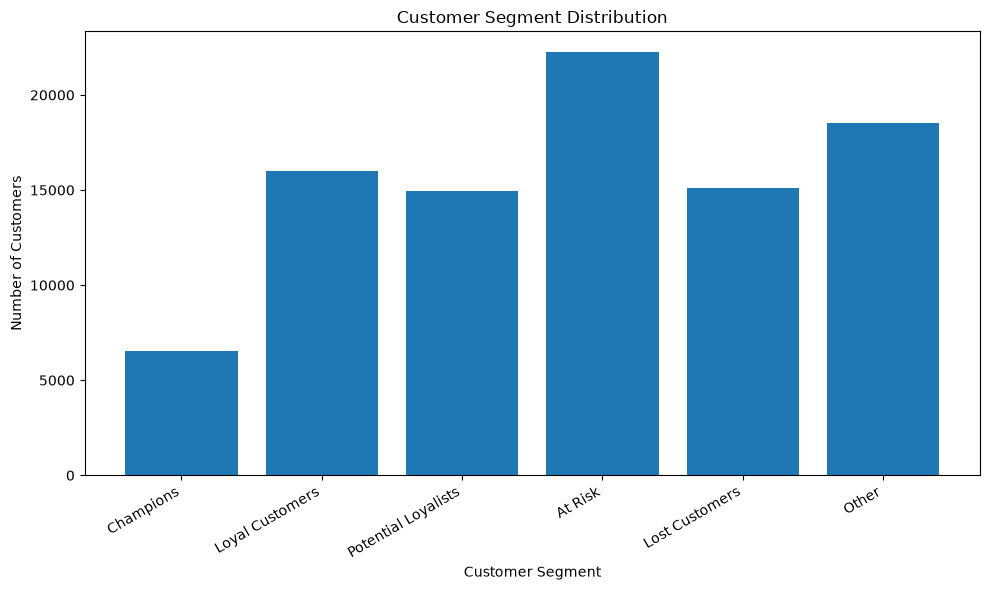

In [26]:
#Customer segment distribution
import matplotlib.pyplot as plt

segment_counts = (
    customer_base["customer_segment"]
    .value_counts()
    .reindex([
        "Champions",
        "Loyal Customers",
        "Potential Loyalists",
        "At Risk",
        "Lost Customers",
        "Other"
    ])
)

plt.figure(figsize=(10, 6))

plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    Chart_Path / "12_customer_segment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

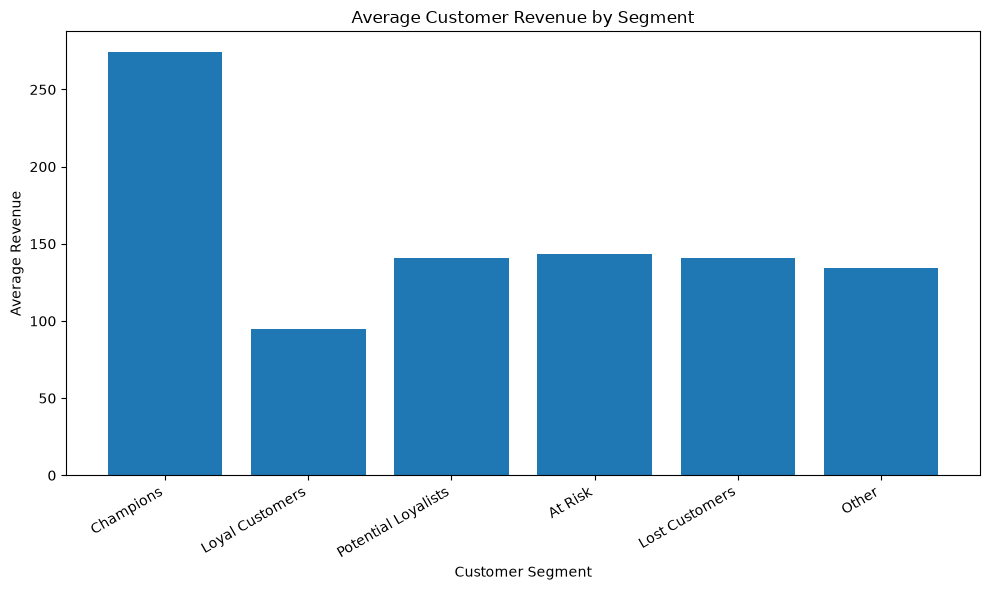

In [27]:
#Average customer value by segment
segment_value = (
    customer_base
    .groupby("customer_segment")["total_revenue"]
    .mean()
    .reindex([
        "Champions",
        "Loyal Customers",
        "Potential Loyalists",
        "At Risk",
        "Lost Customers",
        "Other"
    ])
)

plt.figure(figsize=(10, 6))

plt.bar(
    segment_value.index,
    segment_value.values
)

plt.title("Average Customer Revenue by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Revenue")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    Chart_Path / "13_average_customer_value_by_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

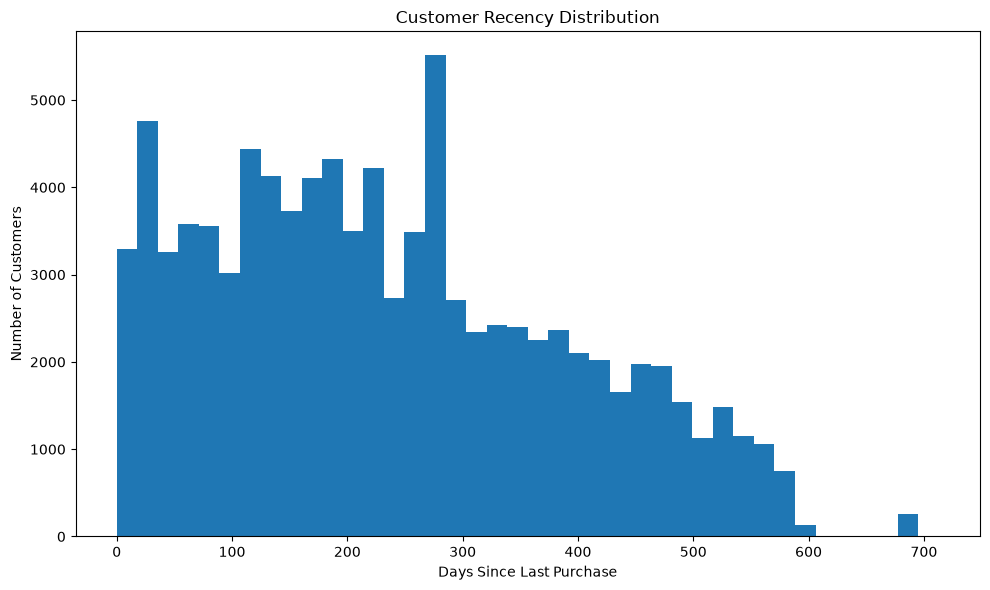

In [28]:
#Recency distribution
plt.figure(figsize=(10, 6))

plt.hist(
    customer_base["recency_days"],
    bins=40
)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    Chart_Path / "14_customer_recency_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

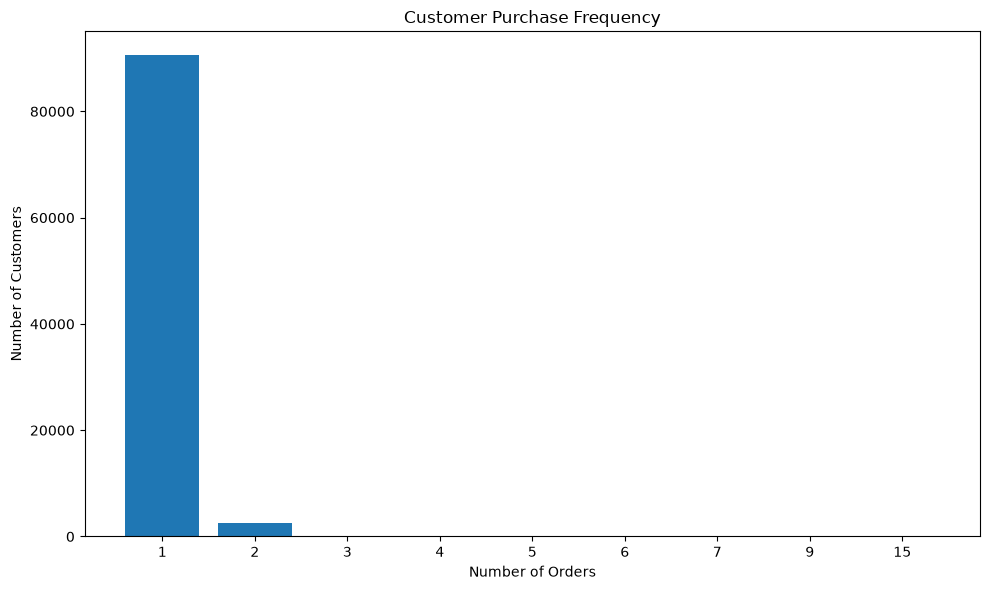

In [29]:
#Frequency distribution
frequency_counts = (
    customer_base["frequency"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

plt.bar(
    frequency_counts.index.astype(str),
    frequency_counts.values
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    Chart_Path / "15_customer_frequency_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

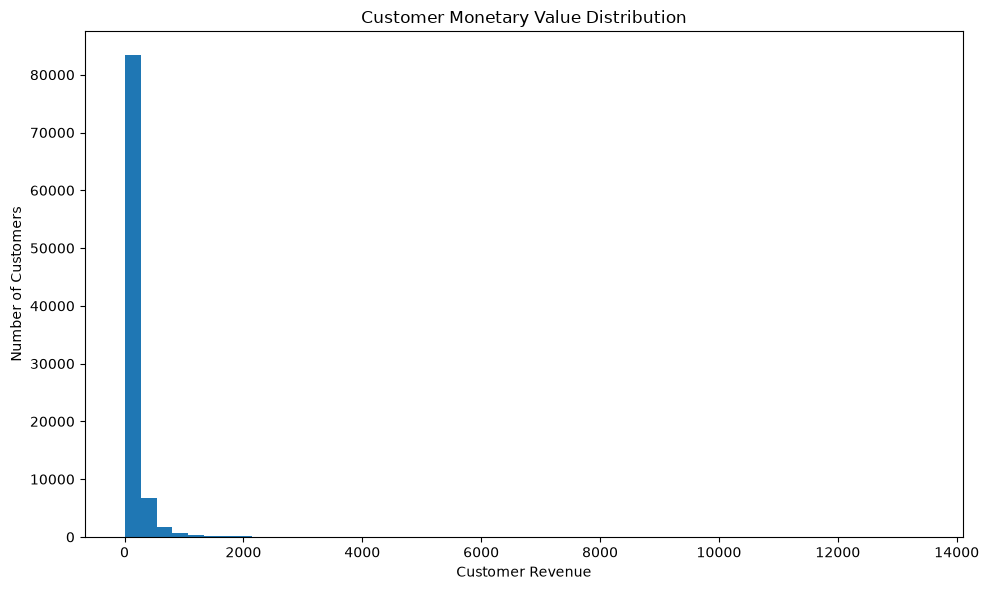

In [30]:
#Monetary value distribution
plt.figure(figsize=(10, 6))

plt.hist(
    customer_base["monetary_value"],
    bins=50
)

plt.title("Customer Monetary Value Distribution")
plt.xlabel("Customer Revenue")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    Chart_Path / "16_customer_monetary_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

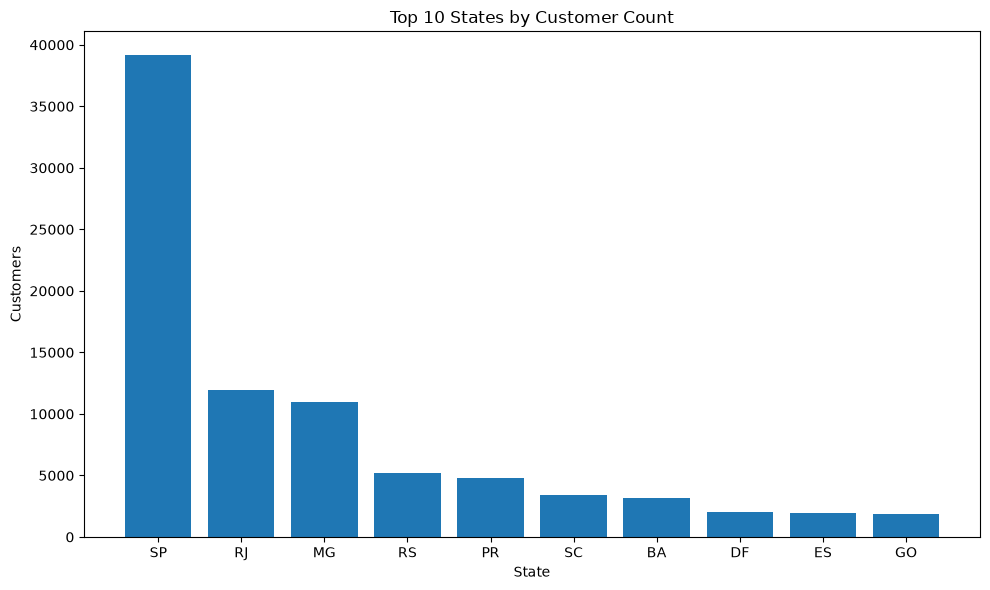

In [32]:
#Customer distribution by state
state_customers = (
    customer_base
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "count"),
        revenue=("total_revenue", "sum")
    )
    .reset_index()
    .sort_values(
        "customers",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.bar(
    state_customers["customer_state"],
    state_customers["customers"]
)

plt.title("Top 10 States by Customer Count")
plt.xlabel("State")
plt.ylabel("Customers")

plt.tight_layout()

plt.savefig(
    Chart_Path / "17_top_customer_states.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
#Save state analysis
state_customers.to_csv(
    Table_Path / "customer_state_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "customer_state_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\customer_state_summary.csv


In [35]:
customer_kpis = pd.DataFrame({
    "metric": [
        "Total Customers",
        "Repeat Customers",
        "Repeat Customer Rate",
        "Average Customer Revenue",
        "Average Orders per Customer",
        "Average Customer AOV",
        "Average Review Score"
    ],
    "value": [
        customer_base["customer_unique_id"].nunique(),

        (customer_base["order_count"] > 1).sum(),

        round(
            (customer_base["order_count"] > 1).mean() * 100,
            2
        ),

        round(
            customer_base["total_revenue"].mean(),
            2
        ),

        round(
            customer_base["order_count"].mean(),
            2
        ),

        round(
            customer_base["customer_aov"].mean(),
            2
        ),

        round(
            customer_base["average_review_score"].mean(),
            2
        )
    ]
})

customer_kpis

,metric,value
0,Total Customers,93342.00
1,Repeat Customers,2800.00
2,Repeat Customer Rate,3.00
3,Average Customer Revenue,141.62
4,Average Orders per Customer,1.03
5,Average Customer AOV,137.51
6,Average Review Score,4.15


In [36]:
customer_kpis.to_csv(
    Table_Path / "customer_kpis.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "customer_kpis.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\customer_kpis.csv
